## 02 - Classification with Audio Embeddings
In this notebook, we will import audio embeddings from json files, and do classification with the vectors

In [1]:
# !pip install sentence-transformers

In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import precision_recall_fscore_support, f1_score, classification_report
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import cross_val_score
from sentence_transformers import SentenceTransformer

In [3]:
# train_fname = "../../data/splits/train.csv"
# dev_fname = "../../data/splits/dev.csv"

# new - load 50/50 splits
train_fname = "../../data/splits/train_50pc.csv"
dev_fname = "../../data/splits/dev_50pc.csv"

# use Pitt set only
# train_fname = "../../data/splits/backup/train_pitt.csv"
# dev_fname = "../../data/splits/backup/dev_pitt.csv"


train_df = pd.read_csv(train_fname)
dev_df = pd.read_csv(dev_fname)

print("Train len =", len(train_df))
print("Dev df =", len(dev_df))

Train len = 83
Dev df = 83


In [4]:
# extra_subset_ratio = 0.8 # use a subset of Pitt dataset. Set to 1.0 to use full set
# extra_subset_ratio = 1 # use a subset of Pitt dataset. Set to 1.0 to use full set


# extra_train_df = pd.read_csv("../../data/splits/train_pitt.csv")
# if extra_subset_ratio < 1:
#     extra_train_df = extra_train_df.sample(frac=extra_subset_ratio, random_state=42)
# extra_train_df.head()
# print("Extra df len =", len(extra_train_df))

In [5]:
train_df.head()

,file_id,text,target
0,adrso021,"Everything you see going on in this picture, g...",CN
1,adrso265,"Now you just look at the picture. Okay, this i...",CN
2,adrso237,Tell me everything that you see going on in th...,AD
3,adrso197,Girls and boys getting her one that stores sto...,AD
4,adrso017,"All right, we have a few more tasks to go thro...",CN


In [6]:
dev_df.head()

,file_id,text,target
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD
1,adrso028,She will find her mother worship trying to dis...,AD
2,adrso032,What's going on well the children are climbing...,AD
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD


### Pre-processing
We will lowercase the text for better efficiency

In [7]:
# extra_train_df["text_lower"] = extra_train_df["text"].apply(lambda text: text.lower().strip())

In [8]:
train_df["text_lower"] = train_df["text"].apply(lambda text: text.lower().strip())
dev_df["text_lower"] = dev_df["text"].apply(lambda text: text.lower().strip())

In [9]:
# print(len(extra_train_df))
# extra_train_df.head()

In [10]:
train_df.head()

,file_id,text,target,text_lower
0,adrso021,"Everything you see going on in this picture, g...",CN,"everything you see going on in this picture, g..."
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,"now you just look at the picture. okay, this i..."
2,adrso237,Tell me everything that you see going on in th...,AD,tell me everything that you see going on in th...
3,adrso197,Girls and boys getting her one that stores sto...,AD,girls and boys getting her one that stores sto...
4,adrso017,"All right, we have a few more tasks to go thro...",CN,"all right, we have a few more tasks to go thro..."


In [11]:
dev_df.head()

,file_id,text,target,text_lower
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,tell me everything that's going on\n\n\n\nthe ...
1,adrso028,She will find her mother worship trying to dis...,AD,she will find her mother worship trying to dis...
2,adrso032,What's going on well the children are climbing...,AD,what's going on well the children are climbing...
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD,okay here's the picture tell me i'll tell you ...
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,tell me what's going on\n\n\n\nall the action ...


In [12]:
# stack up extra-train and train df

# stacked_train_df = pd.concat([train_df, extra_train_df], ignore_index=True, axis=0)

# test with pre-train with extra data only
stack = False  # set to True to combine train_df with extra_train_df
replace = False # set to True to replace train df with extra_train_df (Pitt dataset)

# the combination stack=False and replace=True works best, accuracy=85%, recall=97%
if replace:
    stacked_train_df = extra_train_df
elif stack:
    stacked_train_df = pd.concat([train_df, extra_train_df], ignore_index=True, axis=0)
else:
    # keep the original train_df
    stacked_train_df = train_df

print(len(stacked_train_df))
stacked_train_df.head()

83


,file_id,text,target,text_lower
0,adrso021,"Everything you see going on in this picture, g...",CN,"everything you see going on in this picture, g..."
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,"now you just look at the picture. okay, this i..."
2,adrso237,Tell me everything that you see going on in th...,AD,tell me everything that you see going on in th...
3,adrso197,Girls and boys getting her one that stores sto...,AD,girls and boys getting her one that stores sto...
4,adrso017,"All right, we have a few more tasks to go thro...",CN,"all right, we have a few more tasks to go thro..."


### Build Tfidf Vectorizer

We can use Tfidf Vectorizer to convert text to a fixed-length vector

In [13]:
vectorizer = TfidfVectorizer(max_features=10000)

# corpus = train_df["text_lower"]
corpus = stacked_train_df["text_lower"]
print(len(corpus))
print("Building Tfidf Vectorizer...")
X_train = vectorizer.fit_transform(corpus)
print("Completed")

83
Building Tfidf Vectorizer...
Completed


In [14]:
print(X_train.shape)

(83, 949)


### Load saved Audio embeddings from files

In [15]:
audio_vec_file = "../../data/audio_embed/train_audio_embed.json"
audio_df = pd.read_json(audio_vec_file,
                       orient="records")

# set id to file_id
audio_df.set_index("file_id", inplace=True)
print("Len =", len(audio_df))
audio_df.head()

Len = 237


,audio_embed
file_id,
adrso056,"[0.2023925781, -0.3720703125, -0.2155761719, 0..."
adrso059,"[0.3911132812, -0.1815185547, 0.1787109375, 0...."
adrso060,"[0.5268554688, -0.3059082031, 0.0445251465, 0...."
adrso063,"[0.3513183594, -0.3818359375, -0.114440918, 0...."
adrso068,"[0.4250488281, -0.1889648438, 0.3840332031, 0...."


In [16]:
# append audio_embed column to train and dev set
train_df["audio_embed"] = train_df["file_id"].apply(lambda file_id: audio_df.loc[file_id]["audio_embed"])
assert sum(train_df['audio_embed'].isna()) == 0 # there's no missing data for audio embed
train_df.head()



,file_id,text,target,text_lower,audio_embed
0,adrso021,"Everything you see going on in this picture, g...",CN,"everything you see going on in this picture, g...","[0.0287017822, -0.1733398438, 0.03228759770000..."
1,adrso265,"Now you just look at the picture. Okay, this i...",CN,"now you just look at the picture. okay, this i...","[0.7075195312, -0.4641113281, -0.1889648438, 0..."
2,adrso237,Tell me everything that you see going on in th...,AD,tell me everything that you see going on in th...,"[0.5629882812, -0.2448730469, 0.3037109375, 0...."
3,adrso197,Girls and boys getting her one that stores sto...,AD,girls and boys getting her one that stores sto...,"[0.0982055664, -0.3015136719, -0.3305664062, 0..."
4,adrso017,"All right, we have a few more tasks to go thro...",CN,"all right, we have a few more tasks to go thro...","[0.2524414062, -0.2145996094, -0.0237121582, -..."


In [17]:
# append audio_embed column to train and dev set
dev_df["audio_embed"] = dev_df["file_id"].apply(lambda file_id: audio_df.loc[file_id]["audio_embed"])
assert sum(dev_df['audio_embed'].isna()) == 0 # there's no missing data for audio embed
print(len(dev_df["audio_embed"][0]))
dev_df.head()



512


,file_id,text,target,text_lower,audio_embed
0,adrso025,Tell me everything that's going on\n\n\n\nthe ...,AD,tell me everything that's going on\n\n\n\nthe ...,"[-0.0480651855, -0.2283935547, -0.2570800781, ..."
1,adrso028,She will find her mother worship trying to dis...,AD,she will find her mother worship trying to dis...,"[0.4506835938, -0.3962402344, -0.3923339844, -..."
2,adrso032,What's going on well the children are climbing...,AD,what's going on well the children are climbing...,"[0.6733398438, -0.4057617188, -0.0984497070000..."
3,adrso035,Okay here's the picture tell me I'll tell you ...,AD,okay here's the picture tell me i'll tell you ...,"[0.4221191406, -0.3325195312, -0.30859375, 0.0..."
4,adrso036,Tell me what's going on\n\n\n\nall the action ...,AD,tell me what's going on\n\n\n\nall the action ...,"[0.4145507812, -0.0204925537, 0.04043579100000..."


In [18]:
# llm_embed_path = "../../data/splits/embeddings/mistral/"
# files = ["train_50pc_embed.json",
#          "dev_50pc_embed.json",
#          "test_text_embed.json",
#          "train_pitt_embed.json",
#         ]

# embed_df = []
# for i, fname in enumerate(files):
#     print("Loading saved LLM embeddings from file =", fname)
#     df = pd.read_json(llm_embed_path + fname)
#     print("Len =", len(df))
#     embed_df.append(df)
#     print("Completed")

# print("All completed")

In [19]:
# quick view at train_df embed dataframe
# embed_df[0].head()

In [20]:
# X_train_embed = embed_df[0]["embeddings"]
X_train_embed = train_df["audio_embed"]


print(type(X_train_embed))
print(len(X_train_embed))
print(len(X_train_embed[0])) # should be 512

<class 'pandas.core.series.Series'>
83
512


In [21]:
# convert to np array
X_train_embed = np.array(X_train_embed.tolist())
print(X_train_embed.shape)

(83, 512)


### Create transformer-based sentence embeddings


In [22]:
# vectorizer_embed = SentenceTransformer("all-MiniLM-L12-v2")
# vectorizer_embed = SentenceTransformer("sentence-t5-large") # works best
# vectorizer_embed = SentenceTransformer("all-mpnet-base-v2")
# model = SentenceTransformer("intfloat/e5-mistral-7b-instruct")

# vectorizer_embed = SentenceTransformer("sentence-t5-xl") 
# vectorizer_embed = SentenceTransformer("all-roberta-large-v1") # works better and more consistent than sentence-T5-large
vectorizer_embed = SentenceTransformer("LaBSe") # 85% acc, 94% recall

In [23]:
corpus = stacked_train_df["text_lower"]
print("Creating text embeddings...")
X_train_embed2 = vectorizer_embed.encode(corpus)
# X_train = vectorizer.encode(corpus,
#                             # prompt="Does this person have Alzheimer's Disease (yes/no)?"
#                             prompt="Represent the Medical paragraph for Alzheimer's Disease classification:"
#                            )
print("Completed")


Creating text embeddings...
Completed


In [24]:
print(type(X_train_embed2))
print(X_train_embed2.shape)

<class 'numpy.ndarray'>
(83, 768)


In [25]:
# double check Tfidf vector
print(type(X_train))
print(X_train.shape)

<class 'scipy.sparse._csr.csr_matrix'>
(83, 949)


#### Concate 2 vectors (Tfidf + sentence embeddings)


In [26]:
# test
v1 = [[2, 4, 6],
      [1, 3, 5]
     ]
v2 = [[8, 10],
      [7, 9]
     ]
v3 = np.concatenate((v1, v2), axis=1) # concate on horizontal axis
print(v3) # should be [2, 4, 6, 8, 10], [1, 3, 5, 7, 9]

[[ 2  4  6  8 10]
 [ 1  3  5  7  9]]


In [27]:
concat_train = True
if concat_train:
    # X_train = np.concatenate((X_train.toarray(), X_train_embed, X_train_embed2),
    #                          axis=1
    #                         )
    X_train = np.concatenate((X_train.toarray(), X_train_embed2),
                             axis=1
                            )
    
    # X_train = np.concatenate((X_train.toarray(), X_train_embed),
    #                          axis=1
    #                         )
    # X_train = np.concatenate((X_train_embed, X_train.toarray()),
    #                          axis=1
    #                         )

print(X_train.shape)

(83, 1717)


In [28]:
# switch to embedding train set
# use_embeddings_only = True # set to True to use embedding only, ignoring Tfidf
use_embeddings_only = False # set to True to use embedding only, ignoring Tfidf
if use_embeddings_only:
    X_train = X_train_embed
print(X_train.shape)

(83, 1717)


### Train Logistic regression using combined vector

We can now train a simple logistic regression classifier using processed X_train

In [29]:
# X_train = vectorizer.fit_transform(stacked_train_df["text_lower"])
y_train = stacked_train_df["target"]

print("Training logistic classifier...")
clf = LogisticRegression(random_state=42, max_iter=200).fit(X_train, y_train)

# some setting tweaks to lower the precision -> avoid overfitting
# clf = LogisticRegression(random_state=42, 
#                          solver="newton-cg",
#                          penalty="l2",
#                          tol=0.01,
#                          max_iter=300,
#                         ).fit(X_train, y_train)

# clf = LogisticRegressionCV(random_state=42, 
#                          solver="newton-cg",
#                          penalty="l2",
#                          tol=0.01,
#                          max_iter=500,
#                         ).fit(X_train, y_train)

print("Completed")

Training logistic classifier...
Completed


In [30]:
# # X_train = vectorizer.fit_transform(stacked_train_df["text_lower"])
# from sklearn.neural_network import MLPClassifier

# y_train = stacked_train_df["target"]

# print("Training neural classifier...")
# hidden_size = 50
# clf = MLPClassifier(solver="lbfgs",
#                     # alpha=1e-5,
#                     hidden_layer_sizes=(hidden_size, hidden_size, hidden_size),
#                     # activation="relu",
#                     # shuffle=True,
#                     # learning_rate="constant",
#                     # learning_rate_init=0.0001,
#                     # max_iter=500, 
#                     random_state=42
#                    )
# clf.fit(X_train, y_train)
# print("Completed")

In [31]:
# getting score on train set
train_score = clf.score(X_train, y_train)
print(f"Train accuracy = {train_score*100:.2f} %")

Train accuracy = 93.98 %


In [32]:
# get precision / recall / f1
y_pred = clf.predict(X_train)
print(classification_report(y_train, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.94      0.96      0.95        47
          CN       0.94      0.92      0.93        36

    accuracy                           0.94        83
   macro avg       0.94      0.94      0.94        83
weighted avg       0.94      0.94      0.94        83



### Get accuracy using cross validation

In [33]:
print("Performing cross-validation...")
scores = cross_val_score(clf, X_train, y_train, cv=5)
print("Completed")
print(scores)
print("Average =", np.average(scores))

Performing cross-validation...
Completed
[0.47058824 0.76470588 0.76470588 0.75       0.8125    ]
Average = 0.7125


### Now we can evaluate on dev set

In [34]:
# use_diff_embed_dev = False # set to True to use different embed models for train and dev
# if use_diff_embed_dev:
#     vectorizer_embed = SentenceTransformer("all-mpnet-base-v2") 

In [35]:
X_dev = vectorizer.transform(dev_df["text_lower"])
y_dev = dev_df["target"]
print("X_dev shape =", X_dev.shape)
print("y_dev len =", len(y_dev))

X_dev shape = (83, 949)
y_dev len = 83


In [36]:
# create X_dev embeddings
print("Creating text embeddings...")
X_dev_embed2 = vectorizer_embed.encode(dev_df["text_lower"])
print("Completed")

Creating text embeddings...
Completed


In [37]:
# X_dev_embed = embed_df[1]["embeddings"]
X_dev_embed = dev_df["audio_embed"]
print(type(X_dev_embed))
print(len(X_dev_embed))
print(len(X_dev_embed[0])) # should be 4096

<class 'pandas.core.series.Series'>
83
512


In [38]:
# convert to np array
X_dev_embed = np.array(X_dev_embed.tolist())
print(X_dev_embed.shape)

(83, 512)


In [39]:
# # create X_dev embeddings
# print("Creating text embeddings...")
# X_dev_embed = vectorizer_embed.encode(dev_df["text_lower"])
# print("Completed")

In [40]:
print(type(X_dev_embed))
print(X_dev_embed.shape)

<class 'numpy.ndarray'>
(83, 512)


In [41]:
# double check Tfidf vector
print(type(X_dev))
print(X_dev.shape)

<class 'scipy.sparse._csr.csr_matrix'>
(83, 949)


In [42]:
if concat_train:
    X_dev = np.concatenate((X_dev.toarray(), X_dev_embed2),
                             axis=1
                            )

    # X_dev = np.concatenate((X_dev.toarray(), X_dev_embed, X_dev_embed2),
    #                          axis=1
    #                         )
    # X_dev = np.concatenate((X_dev.toarray(), X_dev_embed),
    #                          axis=1
    #                         )
    # X_dev = np.concatenate((X_dev_embed, X_dev.toarray()),
    #                          axis=1
    #                         )

if use_embeddings_only:
    X_dev = X_dev_embed

print(X_dev.shape)

(83, 1717)


In [43]:
dev_score = clf.score(X_dev, y_dev)
print(f"Dev accuracy = {dev_score*100:.2f} %")

Dev accuracy = 81.93 %


In [44]:
y_pred = clf.predict(X_dev)
print(classification_report(y_dev, y_pred, target_names=["AD", "CN"]))

              precision    recall  f1-score   support

          AD       0.77      0.90      0.83        40
          CN       0.89      0.74      0.81        43

    accuracy                           0.82        83
   macro avg       0.83      0.82      0.82        83
weighted avg       0.83      0.82      0.82        83



The baseline result has improved with additional data from Pitt:
- Accuracy improved to 78% compared with 74% in previous baseline
- Recall improved to 89%, compared with 76% in previous baseline
- Average 10-fold accuracy improved to 80% from 76% 

If we pre-train with Pitt dataset only, without using our train set at all:
- the accuracy dropped slightly from 79% to 77%
- but recall improved from 90% to 94%

In [45]:
### Process prediction for test set

In [46]:
test_fname = "../../data/splits/test_text.csv"
test_df = pd.read_csv(test_fname)
print("Test df =", len(test_df))
test_df["text_lower"] = test_df["text"].apply(lambda text: text.lower().strip())
test_df.head()

Test df = 71


,ID,Prediction,text,text_lower
0,adrsdt15,NaN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying..."
1,adrsdt40,NaN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...
2,adrsdt26,NaN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an..."
3,adrsdt67,NaN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind..."
4,adrsdt58,NaN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...


In [47]:
# append audio_embed column to train and dev set
test_df["audio_embed"] = test_df["ID"].apply(lambda file_id: audio_df.loc[file_id]["audio_embed"])
assert sum(test_df['audio_embed'].isna()) == 0 # there's no missing data for audio embed
print(len(test_df["audio_embed"][0]))
test_df.head()

512


,ID,Prediction,text,text_lower,audio_embed
0,adrsdt15,NaN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying...","[0.2292480469, 0.0360107422, 0.2177734375, -0...."
1,adrsdt40,NaN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...,"[0.275390625, -0.0616760254, 0.2666015625, 0.1..."
2,adrsdt26,NaN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an...","[0.572265625, 0.0052719116, 0.1276855469, 0.04..."
3,adrsdt67,NaN,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind...","[0.3376464844, 0.2379150391, 0.0628662109, 0.1..."
4,adrsdt58,NaN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...,"[0.2253417969, -0.0270233154, 0.0426635742, 0...."


In [48]:
X_test = vectorizer.transform(test_df["text_lower"])


In [49]:
# create X_test embeddings
print("Creating text embeddings...")
X_test_embed2 = vectorizer_embed.encode(test_df["text_lower"])
print("Completed")

Creating text embeddings...
Completed


In [50]:
# X_test_embed = embed_df[2]["embeddings"]
X_test_embed = test_df["audio_embed"]

print(type(X_test_embed))
print(len(X_test_embed)) # should be 71
print(len(X_test_embed[0])) # should be 4096

<class 'pandas.core.series.Series'>
71
512


In [51]:
# convert to np array
X_test_embed = np.array(X_test_embed.tolist())
print(X_test_embed.shape)

(71, 512)


In [52]:
if concat_train:
    X_test = np.concatenate((X_test.toarray(), X_test_embed2),
                             axis=1
                            )

    # X_test = np.concatenate((X_test.toarray(), X_test_embed, X_test_embed2),
    #                          axis=1
    #                         )
    # X_test = np.concatenate((X_test.toarray(), X_test_embed),
    #                          axis=1
    #                         )
    # X_test = np.concatenate((X_test_embed, X_test.toarray()),
    #                          axis=1
    #                         )
if use_embeddings_only:
    X_test = X_test_embed
    
print(X_test.shape)

(71, 1717)


In [53]:
test_df["Prediction"] = clf.predict(X_test)
test_df.head()

,ID,Prediction,text,text_lower,audio_embed
0,adrsdt15,CN,"I see oh boy, almost falling on a stool trying...","i see oh boy, almost falling on a stool trying...","[0.2292480469, 0.0360107422, 0.2177734375, -0...."
1,adrsdt40,CN,Well the kids are trying to get the cookies an...,well the kids are trying to get the cookies an...,"[0.275390625, -0.0616760254, 0.2666015625, 0.1..."
2,adrsdt26,CN,"Okay, this is a family setting in a kitchen an...","okay, this is a family setting in a kitchen an...","[0.572265625, 0.0052719116, 0.1276855469, 0.04..."
3,adrsdt67,AD,"Oh, what do I see in this picture? This remind...","oh, what do i see in this picture? this remind...","[0.3376464844, 0.2379150391, 0.0628662109, 0.1..."
4,adrsdt58,CN,While the young boy is reaching for a cookie j...,while the young boy is reaching for a cookie j...,"[0.2253417969, -0.0270233154, 0.0426635742, 0...."


In [54]:
# convert to 0/1 to be consistent to ground truth
label2binary = lambda label: "0" if label=="0" or label.lower().strip() == "cn" else "1"
assert label2binary("CN") == "0"
assert label2binary("AD") == "1"
assert label2binary("0") == "0"
assert label2binary("1") == "1"

print("Passed")

Passed


In [55]:
# apply to prediction column
test_df["Prediction"] = test_df["Prediction"].apply(label2binary)
# write to prediction output file
output_df = test_df.drop(columns=["text", "text_lower", "audio_embed"])
output_df.head()

,ID,Prediction
0,adrsdt15,0
1,adrsdt40,0
2,adrsdt26,0
3,adrsdt67,1
4,adrsdt58,0


In [56]:
output_path = "../../evaluation/"
fname = "test_results_task1_audio_embed.csv"
output_df.to_csv(output_path + fname,
                 index=False
                )
print("Completed")

Completed


### Evaluation output for test set 

Using Tfidf + Wav2vec2 embeddings

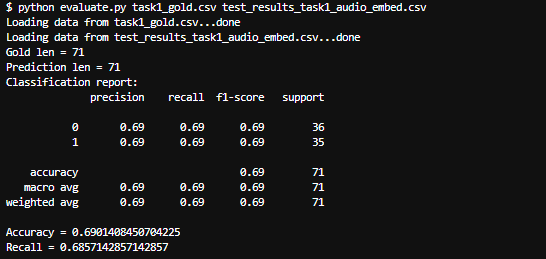